In [2]:
import numpy as np, pandas as pd, wfdb
from pathlib import Path

DATA_DIR = Path("/media/ehsan/MyFiles1/FraUAS/HIS Project/PTB-XL")

FS, ENC, PRED, STRIDE, SEED = 100, 500, 300, 100, 42
N_PATIENTS = {"train": 64, "val": 24}          # his pilot cohort
LEADS = ['I','II','III','AVR','AVL','AVF','V1','V2','V3','V4','V5','V6']

df = pd.read_csv(DATA_DIR / "ptbxl_database.csv", index_col="ecg_id")
df["patient_id"] = df["patient_id"].astype(int)
df["split"] = np.select([df.strat_fold <= 8, df.strat_fold == 9],
                        ["train", "val"], default="test")

def sample_by_patient(split, n, seed):
    sub = df[df.split == split]
    pats = np.sort(sub.patient_id.unique())
    chosen = np.random.default_rng(seed).choice(pats, size=n, replace=False)
    return sub[sub.patient_id.isin(chosen)]      # all records of chosen patients

cohort = {"train": sample_by_patient("train", N_PATIENTS["train"], SEED),
          "val":   sample_by_patient("val",   N_PATIENTS["val"],   SEED + 1)}

for s, c in cohort.items():
    print(s, "patients:", c.patient_id.nunique(), "records:", len(c))

train patients: 64 records: 79
val patients: 24 records: 25


In [3]:
def load_windows(sub, split):
    X, meta = [], []
    for ecg_id, r in sub.iterrows():
        sig = wfdb.rdrecord(str(DATA_DIR / r.filename_lr)).p_signal.astype(np.float32)  # (1000, 12)
        assert not np.isnan(sig).any(), f"NaN in ecg {ecg_id}"
        starts = range(0, sig.shape[0] - (ENC + PRED) + 1, STRIDE) if split == "train" else [0]
        for st in starts:
            X.append(sig[st: st + ENC + PRED])
            meta.append(dict(window_id=f"{ecg_id}_{st}", ecg_id=ecg_id,
                             patient_id=r.patient_id, split=split, start=st))
    return np.stack(X), pd.DataFrame(meta)

data = {s: load_windows(cohort[s], s) for s in cohort}
for s, (X, m) in data.items():
    print(s, X.shape)          # train: (n_records*3, 800, 12)   val: (n_records, 800, 12)

train (237, 800, 12)
val (25, 800, 12)


In [4]:
Xtr, mtr = data["train"]
enc = Xtr[:, :ENC, :].reshape(-1, 12)            # observed part of training windows ONLY
MED = np.median(enc, axis=0)
IQR = np.percentile(enc, 75, axis=0) - np.percentile(enc, 25, axis=0)
IQR[IQR == 0] = 1.0

# --- leakage checks ---
p_tr, p_va = set(data["train"][1].patient_id), set(data["val"][1].patient_id)
assert p_tr.isdisjoint(p_va), "patient overlap between train and val!"
assert not (set(data["train"][1].ecg_id) & set(data["val"][1].ecg_id))
print("✅ patients disjoint | scaler fit on training encoder samples only")

✅ patients disjoint | scaler fit on training encoder samples only


In [5]:
def to_long(X, meta):
    n = len(X)
    Xs = (X - MED) / IQR
    out = pd.DataFrame(Xs.reshape(-1, 12), columns=[f"lead_{l}" for l in LEADS])
    out["window_id"] = np.repeat(meta.window_id.values, ENC + PRED)
    out["time_idx"]  = np.tile(np.arange(ENC + PRED), n)
    out["static_dummy"] = 0.0                    # placeholder static; see note below
    return out

long = {s: to_long(*data[s]) for s in data}
print(long["train"].shape, long["val"].shape)
long["train"].head(3)

(189600, 15) (20000, 15)


,lead_I,lead_II,lead_III,lead_AVR,lead_AVL,lead_AVF,lead_V1,lead_V2,lead_V3,lead_V4,lead_V5,lead_V6,window_id,time_idx,static_dummy
0,2.747126,2.486956,0.453608,-2.966292,1.217949,1.705263,-3.582278,0.114094,1.278788,-1.155405,-0.742188,-2.046729,865_0,0,0.0
1,3.022989,2.634783,0.391753,-3.191011,1.410256,1.768421,-3.582278,0.154362,1.327273,-1.081081,-0.609375,-1.803738,865_0,1,0.0
2,3.528736,2.947826,0.298969,-3.640449,1.743590,1.905263,-3.848101,0.228188,1.290909,-0.858108,-0.281250,-1.420561,865_0,2,0.0


In [6]:
def patient_macro_mae(pred, true, meta):
    per_win = np.abs(pred - true).mean(axis=(1, 2))
    return pd.Series(per_win).groupby(meta.patient_id.values).mean().mean()

Xv, mv = data["val"]
true = Xv[:, ENC:, :]
persist = np.repeat(Xv[:, ENC-1:ENC, :], PRED, axis=1)
const   = np.broadcast_to(MED, true.shape)       # training-median constant baseline

print("persistence :", round(patient_macro_mae(persist, true, mv), 6))   # his: 0.162705
print("train median:", round(patient_macro_mae(const,   true, mv), 6))   # his: 0.107705

persistence : 0.159326
train median: 0.113759


In [8]:
Path("cache").mkdir(exist_ok=True)
np.savez_compressed("cache/ptbxl_100hz_5to3.npz",
                    Xtr=data["train"][0], Xva=data["val"][0], MED=MED, IQR=IQR)
data["train"][1].to_csv("cache/meta_train.csv", index=False)
data["val"][1].to_csv("cache/meta_val.csv", index=False)

In [10]:
import torch, lightning.pytorch as pl
from pytorch_forecasting import TimeSeriesDataSet, TemporalFusionTransformer
from pytorch_forecasting.data import MultiNormalizer, TorchNormalizer, NaNLabelEncoder
from pytorch_forecasting.metrics import MultiLoss, MAE

import warnings
warnings.filterwarnings("ignore", message="The given NumPy array is not writable")
warnings.filterwarnings("ignore", message="Found .* unknown classes")

targets = [f"lead_{l}" for l in LEADS]

# data is already scaled with training-only median/IQR, so no further target normalization
identity = lambda: TorchNormalizer(method="identity", center=False)

train_ds = TimeSeriesDataSet(
    long["train"],
    time_idx="time_idx",
    target=targets,
    group_ids=["window_id"],
    min_encoder_length=ENC, max_encoder_length=ENC,
    min_prediction_length=PRED, max_prediction_length=PRED,
    static_reals=["static_dummy"],
    time_varying_unknown_reals=targets,          # observed only in the encoder
    add_relative_time_idx=True,                  # the only known-future input
    target_normalizer=MultiNormalizer([identity() for _ in targets]),
    scalers={"static_dummy": None},
    categorical_encoders={"window_id": NaNLabelEncoder(add_nan=True)},  # val windows are unseen groups
)

val_ds = TimeSeriesDataSet.from_dataset(train_ds, long["val"], stop_randomization=True)

print("train samples:", len(train_ds), "| val samples:", len(val_ds))   # expect 237 and 25

train_dl = train_ds.to_dataloader(train=True,  batch_size=16, num_workers=0)
val_dl   = val_ds.to_dataloader(train=False, batch_size=16, num_workers=0)

train samples: 237 | val samples: 25


In [12]:
x, y = next(iter(val_dl))
print("batch keys:", sorted(x.keys()))

print("encoder_cont:", tuple(x["encoder_cont"].shape))     # expect (B, 500, 14): 12 leads + relative_time_idx + static_dummy
print("decoder_cont:", tuple(x["decoder_cont"].shape))     # expect (B, 300, 14)
print("encoder lengths:", x["encoder_lengths"].unique().tolist())   # expect [500]
print("decoder lengths:", x["decoder_lengths"].unique().tolist())   # expect [300]

# targets for the first val batch, stacked to (B, 300, 12)
tgt = y[0]
tgt = torch.stack(list(tgt), dim=-1) if isinstance(tgt, (list, tuple)) else tgt
print("target:", tuple(tgt.shape))                           # expect (B, 300, 12)

# compare against our own scaled future values, matched by window_id
Xv, mv = data["val"]
ids = val_ds.decoded_index["window_id"].values[: tgt.shape[0]]
rows = [mv.index[mv.window_id == w][0] for w in ids]
ref = (Xv[rows, ENC:, :] - MED) / IQR
print("max |dataloader - reference|:", float(np.abs(tgt.numpy() - ref).max()))   # expect ~1e-5 or smaller

batch keys: ['decoder_cat', 'decoder_cont', 'decoder_lengths', 'decoder_target', 'decoder_time_idx', 'encoder_cat', 'encoder_cont', 'encoder_lengths', 'encoder_target', 'groups', 'target_scale']
encoder_cont: (16, 500, 14)
decoder_cont: (16, 300, 14)
encoder lengths: [500]
decoder lengths: [300]
target: (16, 300, 12)
max |dataloader - reference|: 0.0


In [15]:
import warnings, logging
for msg in ["The given NumPy array is not writable",
            "Found .* unknown classes",
            ".*is an instance of `nn.Module` and is already saved.*",
            ".*does not have many workers.*",
            ".*treespec.*"]:
    warnings.filterwarnings("ignore", message=msg)

pl.seed_everything(SEED)

tft = TemporalFusionTransformer.from_dataset(
    train_ds,
    hidden_size=16,
    attention_head_size=2,
    hidden_continuous_size=8,
    dropout=0.1,
    learning_rate=1e-3,
    loss=MultiLoss([MAE() for _ in targets]),    # point forecast, comparable to his MAE
    output_size=[1] * len(targets),
    log_interval=-1,
    reduce_on_plateau_patience=3,
)
print("Parameters:", sum(p.numel() for p in tft.parameters()))

Seed set to 42


Parameters: 24156


In [16]:
import warnings, logging
for msg in ["The given NumPy array is not writable",
            "Found .* unknown classes",
            ".*is an instance of `nn.Module` and is already saved.*",
            ".*does not have many workers.*",
            ".*treespec.*"]:
    warnings.filterwarnings("ignore", message=msg)

import time
trainer = pl.Trainer(
    max_epochs=1, accelerator="cpu",
    limit_train_batches=3, limit_val_batches=2,
    gradient_clip_val=0.1,
    enable_checkpointing=False, logger=False,
)
t0 = time.time()
trainer.fit(tft, train_dataloaders=train_dl, val_dataloaders=val_dl)
print(f"Smoke test took {time.time()-t0:.1f}s for 3 train batches + 2 val batches")

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

   | Name                               | Type                            | Params | Mode  | FLOPs
--------------------------------------------------------------------------------------------------------
0  | loss                               | MultiLoss                       | 0      | train | 0    
1  | logging_metrics                    | ModuleList                      | 0      | train | 0    
2  | input_embeddings                   | MultiEmbedding                  | 0      | train | 0    
3  | prescalers                         | ModuleDict                      | 224    | train | 0    
4  | static_variable_selection          | VariableSelectionNetwork        | 528    | train | 0

Sanity Checking: |                                       | 0/? [00:00<?, ?it/s]

Training: |                                              | 0/? [00:00<?, ?it/s]

Validation: |                                            | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=1` reached.


Smoke test took 1.0s for 3 train batches + 2 val batches


In [17]:
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger

pl.seed_everything(SEED)

tft = TemporalFusionTransformer.from_dataset(
    train_ds,
    hidden_size=16, attention_head_size=2, hidden_continuous_size=8,
    dropout=0.1, learning_rate=1e-3,
    loss=MultiLoss([MAE() for _ in targets]),
    output_size=[1] * len(targets),
    log_interval=-1, reduce_on_plateau_patience=3,
)

ckpt = ModelCheckpoint(dirpath="cache/tft_ckpt", monitor="val_loss", mode="min",
                       save_top_k=1, filename="tft-best")
early = EarlyStopping(monitor="val_loss", mode="min", patience=8)
logger = CSVLogger("cache", name="tft_logs")

trainer = pl.Trainer(
    max_epochs=40, accelerator="cpu", gradient_clip_val=0.1,
    callbacks=[ckpt, early], logger=logger, enable_progress_bar=True,
)
t0 = time.time()
trainer.fit(tft, train_dataloaders=train_dl, val_dataloaders=val_dl)
print(f"Training took {time.time()-t0:.0f}s | best epoch val_loss: {ckpt.best_model_score:.4f}")
print("Best checkpoint:", ckpt.best_model_path)

Seed set to 42
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

   | Name                               | Type                            | Params | Mode  | FLOPs
--------------------------------------------------------------------------------------------------------
0  | loss                               | MultiLoss                       | 0      | train | 0    
1  | logging_metrics                    | ModuleList                      | 0      | train | 0    
2  | input_embeddings                   | MultiEmbedding                  | 0      | train | 0    
3  | prescalers                         | ModuleDict                      | 224    | train | 0    
4  | static_variable_selection          | VariableSelectionNetwork        | 528

Sanity Checking: |                                       | 0/? [00:00<?, ?it/s]

/home/ehsan/.venvs/ptbxl_tsa_venv/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:321: The number of training batches (14) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Training: |                                              | 0/? [00:00<?, ?it/s]

Validation: |                                            | 0/? [00:00<?, ?it/s]

Validation: |                                            | 0/? [00:00<?, ?it/s]

... (9 outputs left out)

Validation: |                                            | 0/? [00:00<?, ?it/s]

Validation: |                                            | 0/? [00:00<?, ?it/s]

Validation: |                                            | 0/? [00:00<?, ?it/s]

Training took 40s | best epoch val_loss: 11.5276
Best checkpoint: /media/ehsan/MyFiles1/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/cache/tft_ckpt/tft-best.ckpt


In [18]:
best = TemporalFusionTransformer.load_from_checkpoint(ckpt.best_model_path)
best.eval()

Xv, mv = data["val"]
id2row = {w: i for i, w in enumerate(mv.window_id)}

preds, order = [], []
with torch.no_grad():
    # val_dl was created with train=False, so batches follow val_ds.decoded_index order
    for x, y in val_dl:
        out = best(x)["prediction"]                      # list of 12 tensors, each (B, 300, 1)
        p = torch.stack([o.squeeze(-1) for o in out], dim=-1)   # (B, 300, 12)
        preds.append(p.numpy())
preds = np.concatenate(preds)                             # (25, 300, 12), scaled units

ids = val_ds.decoded_index["window_id"].values
rows = [id2row[w] for w in ids]
pred_mV = preds * IQR + MED                               # back to mV
true_mV = Xv[rows, ENC:, :]
meta_v  = mv.iloc[rows].reset_index(drop=True)

mae   = patient_macro_mae(pred_mV, true_mV, meta_v)
rmse  = float(np.sqrt(((pred_mV - true_mV) ** 2).mean()))
print(f"TFT          patient-macro MAE: {mae:.6f} mV | RMSE: {rmse:.6f}")

persist = np.repeat(Xv[rows, ENC-1:ENC, :], PRED, axis=1)
const   = np.broadcast_to(MED, true_mV.shape)
for name, b in [("persistence", persist), ("train median", const)]:
    print(f"{name:12s} patient-macro MAE: {patient_macro_mae(b, true_mV, meta_v):.6f} mV | "
          f"RMSE: {float(np.sqrt(((b - true_mV) ** 2).mean())):.6f}")

TFT          patient-macro MAE: 0.112751 mV | RMSE: 0.256715
persistence  patient-macro MAE: 0.159326 mV | RMSE: 0.334166
train median patient-macro MAE: 0.113759 mV | RMSE: 0.256690


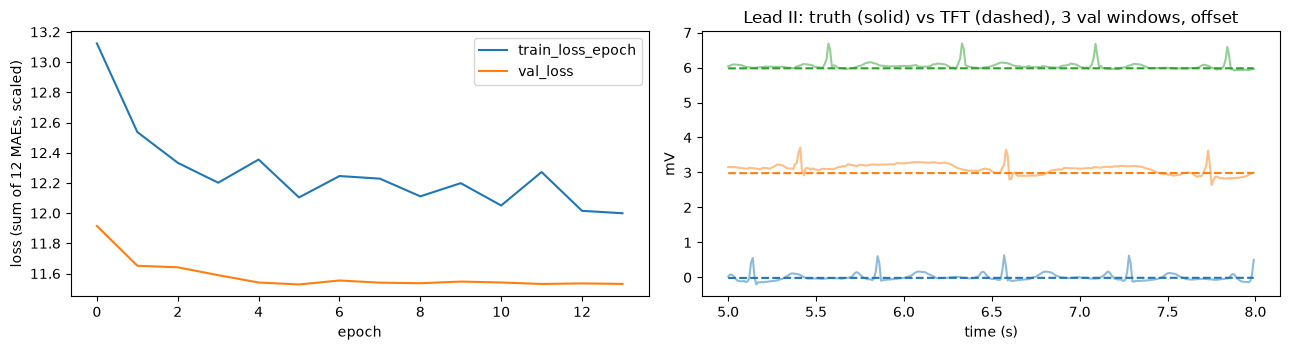

In [19]:
import matplotlib.pyplot as plt

log = pd.read_csv(f"{logger.log_dir}/metrics.csv")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for col in ["train_loss_epoch", "val_loss"]:
    if col in log:
        s = log[["epoch", col]].dropna()
        ax[0].plot(s.epoch, s[col], label=col)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss (sum of 12 MAEs, scaled)"); ax[0].legend()

lead = LEADS.index("II")
t_obs = np.arange(ENC - 200, ENC) / FS
t_fut = np.arange(ENC, ENC + PRED) / FS
for k, c in zip([0, 5, 10], ["C0", "C1", "C2"]):
    i = rows.index(rows[k])
    ax[1].plot(t_fut, true_mV[i, :, lead] + 3 * (k // 5), c, alpha=.5)
    ax[1].plot(t_fut, pred_mV[i, :, lead] + 3 * (k // 5), c, ls="--")
ax[1].set_title("Lead II: truth (solid) vs TFT (dashed), 3 val windows, offset")
ax[1].set_xlabel("time (s)"); ax[1].set_ylabel("mV")
plt.tight_layout(); plt.show()

In [20]:
# (a) How much does TFT deviate from the constant median at all?
dev = np.abs(pred_mV - MED)
print(f"mean |TFT - median|: {dev.mean():.5f} mV   (true signal's own mean |x - median|: "
      f"{np.abs(true_mV - MED).mean():.5f} mV)")
print("TFT std over time (avg per window/lead):", f"{pred_mV.std(axis=1).mean():.5f} mV")

# (b) Paired patient-level bootstrap: TFT minus median (negative favors TFT), like his report
def per_patient(pred, true, meta):
    w = np.abs(pred - true).mean(axis=(1, 2))
    return pd.Series(w).groupby(meta.patient_id.values).mean()

d = (per_patient(pred_mV, true_mV, meta_v) - per_patient(const, true_mV, meta_v)).values
rng = np.random.default_rng(SEED)
boot = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(1000)]
print(f"delta MAE (TFT - median): {d.mean():+.6f} mV | 95% CI [{np.percentile(boot,2.5):+.6f}, {np.percentile(boot,97.5):+.6f}] "
      f"| patients: {len(d)}")

# (c) Leakage mutation test: scramble every future (decoder) value the model could see.
x, _ = next(iter(val_dl))
names = train_ds.reals                                  # column order of *_cont tensors
lead_idx = [names.index(t) for t in targets]
with torch.no_grad():
    p0 = torch.stack([o.squeeze(-1) for o in best(x)["prediction"]], -1)
    x2 = {k: (v.clone() if torch.is_tensor(v) else v) for k, v in x.items()}
    x2["decoder_cont"][:, :, lead_idx] = torch.randn_like(x2["decoder_cont"][:, :, lead_idx]) * 10
    p1 = torch.stack([o.squeeze(-1) for o in best(x2)["prediction"]], -1)
print("max change in prediction after scrambling the future:", float((p0 - p1).abs().max()))

mean |TFT - median|: 0.01140 mV   (true signal's own mean |x - median|: 0.11331 mV)
TFT std over time (avg per window/lead): 0.00271 mV
delta MAE (TFT - median): -0.001007 mV | 95% CI [-0.001949, -0.000208] | patients: 24
max change in prediction after scrambling the future: 0.0


In [21]:
# Compute step-wise lead-averaged MAE across the 300 steps
# pred_mV and true_mV are shaped (25, 300, 12)
mae_step_tft = np.abs(pred_mV - true_mV).mean(axis=(0, 2))
np.save("cache/tft_step_mae.npy", mae_step_tft)

print("TFT step-wise MAE computed and cached to cache/tft_step_mae.npy")
print(f"  Step 1 (0.01s) MAE: {mae_step_tft[0]:.6f} mV")
print(f"  Step 150 (1.50s) MAE: {mae_step_tft[149]:.6f} mV")
print(f"  Step 300 (3.00s) MAE: {mae_step_tft[299]:.6f} mV")

TFT step-wise MAE computed and cached to cache/tft_step_mae.npy
  Step 1 (0.01s) MAE: 0.090698 mV
  Step 150 (1.50s) MAE: 0.116815 mV
  Step 300 (3.00s) MAE: 0.123185 mV


In [22]:
# Measure peak dynamic range and spectral retention on Lead II
lead = LEADS.index("II")
true_peaks = true_mV[:, :, lead].max(axis=1) - true_mV[:, :, lead].min(axis=1)
tft_peaks = pred_mV[:, :, lead].max(axis=1) - pred_mV[:, :, lead].min(axis=1)

amp_ratio = (tft_peaks / true_peaks).mean() * 100
print(f"Lead II Peak-to-Peak Dynamic Range:")
print(f"  Ground Truth Signal : {true_peaks.mean():.4f} mV")
print(f"  TFT Forecast        : {tft_peaks.mean():.4f} mV ({amp_ratio:.2f}% of true amplitude)")

# Frequency domain energy via FFT
true_fft = np.abs(np.fft.rfft(true_mV[:, :, lead], axis=1))
tft_fft = np.abs(np.fft.rfft(pred_mV[:, :, lead], axis=1))
hf_ratio = (tft_fft[:, 5:].sum() / true_fft[:, 5:].sum()) * 100
print(f"  High-Frequency Spectral Energy (>1.6 Hz): {hf_ratio:.2f}% retained")

Lead II Peak-to-Peak Dynamic Range:
  Ground Truth Signal : 1.0666 mV
  TFT Forecast        : 0.0059 mV (0.66% of true amplitude)
  High-Frequency Spectral Energy (>1.6 Hz): 0.47% retained


In [23]:
tft_results_df = pd.DataFrame([
    {
        "Model": "TFT",
        "Params": 24156,
        "Val_MAE_mV": round(mae, 6),
        "Val_RMSE": round(rmse, 6),
        "Delta_MAE_vs_Median_mV": round(d.mean(), 6),
        "CI_95_Low": round(np.percentile(boot, 2.5), 6),
        "CI_95_High": round(np.percentile(boot, 97.5), 6),
        "Temporal_Std_mV": round(float(pred_mV.std(axis=1).mean()), 5),
    }
])
tft_results_df.to_csv("cache/tft_metrics.csv", index=False)
print("Saved cache/tft_metrics.csv")

Saved cache/tft_metrics.csv


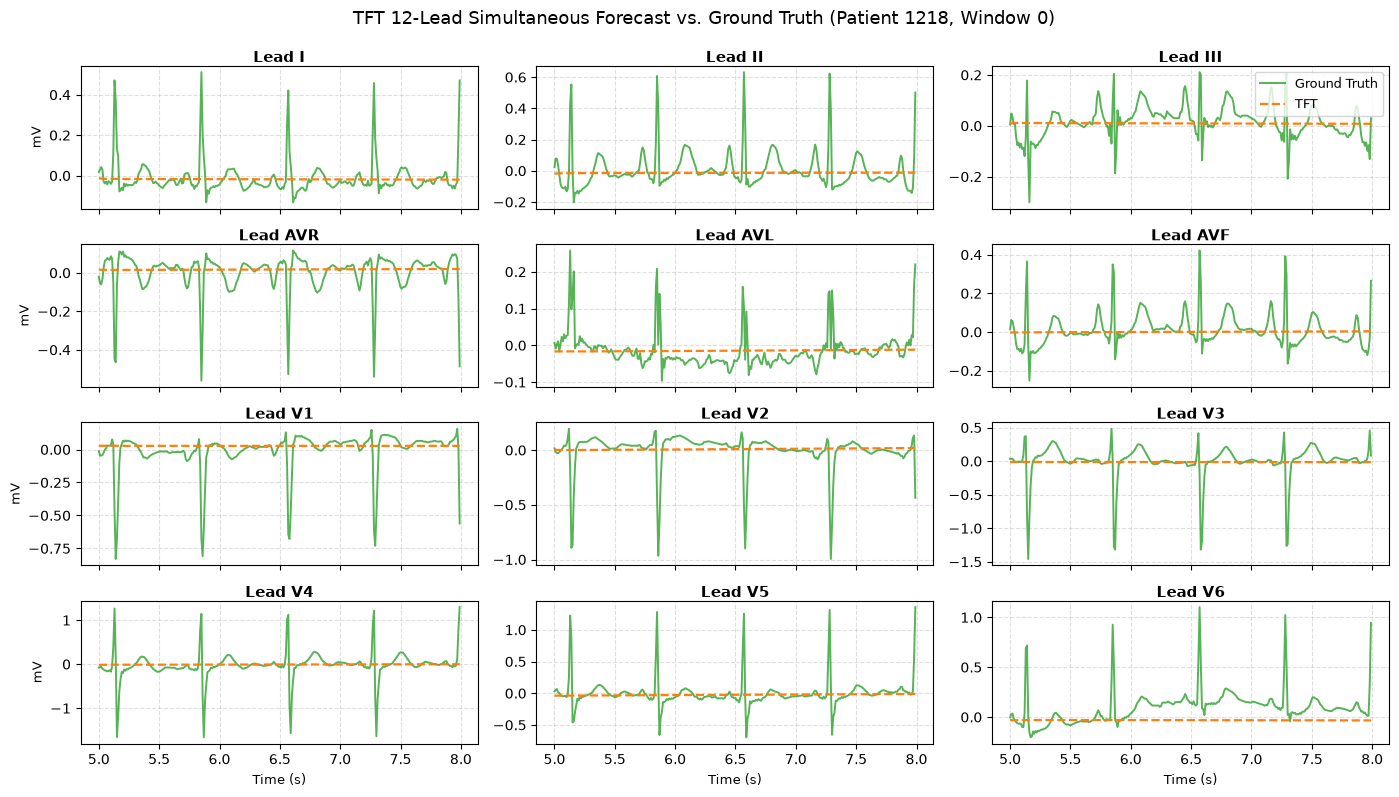

Figure saved to reports/figures/fig3_tft_12lead_spatial_grid.png


In [24]:
fig_dir = Path("reports/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

# Plot validation window 0 across all 12 leads
win_idx = 0
time_axis = np.arange(ENC, ENC + PRED) / FS

fig, axes = plt.subplots(4, 3, figsize=(14, 8), sharex=True)
axes = axes.flatten()
lead_order = ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

for i, lead_name in enumerate(lead_order):
    l_idx = LEADS.index(lead_name)
    ax = axes[i]
    ax.plot(time_axis, true_mV[win_idx, :, l_idx], label="Ground Truth", color="#2ca02c", alpha=0.8, linewidth=1.4)
    ax.plot(time_axis, pred_mV[win_idx, :, l_idx], label="TFT", color="#ff7f0e", linestyle="--", linewidth=1.6)
    
    ax.set_title(f"Lead {lead_name}", fontsize=11, fontweight="bold", pad=2)
    ax.grid(True, linestyle="--", alpha=0.4)
    if i % 3 == 0:
        ax.set_ylabel("mV", fontsize=9)
    if i >= 9:
        ax.set_xlabel("Time (s)", fontsize=9)

axes[2].legend(loc="upper right", fontsize=9)
pat_id = meta_v.iloc[win_idx]["patient_id"]
fig.suptitle(f"TFT 12-Lead Simultaneous Forecast vs. Ground Truth (Patient {pat_id}, Window {win_idx})", fontsize=13, y=0.99)
plt.tight_layout()

plt.savefig(fig_dir / "fig3_tft_12lead_spatial_grid.png", dpi=300)
plt.savefig(fig_dir / "fig3_tft_12lead_spatial_grid.pdf")
plt.show()
print(f"Figure saved to {fig_dir / 'fig3_tft_12lead_spatial_grid.png'}")

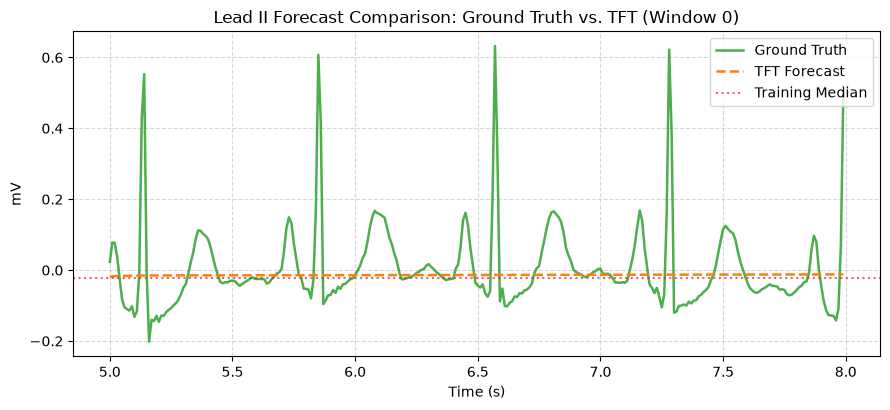

Figure saved to reports/figures/fig4_lead2_tft_vs_truth.png


In [25]:
# Check if PatchTST predictions are cached; if so, load them
patch_ckpt_path = Path("cache/patchtst_ckpt/patchtst-best.pt")

# If patchtst metrics exist, we can plot the direct comparison
win_k = 0
lead_k = LEADS.index("II")
t_fut = np.arange(ENC, ENC + PRED) / FS

plt.figure(figsize=(9, 4.2))
plt.plot(t_fut, true_mV[win_k, :, lead_k], label="Ground Truth", color="#2ca02c", linewidth=1.8, alpha=0.85)
plt.plot(t_fut, pred_mV[win_k, :, lead_k], label="TFT Forecast", color="#ff7f0e", linestyle="--", linewidth=1.8)
plt.axhline(MED[lead_k], color="#d62728", linestyle=":", label="Training Median", alpha=0.7)

plt.title(f"Lead II Forecast Comparison: Ground Truth vs. TFT (Window {win_k})", fontsize=12)
plt.xlabel("Time (s)")
plt.ylabel("mV")
plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(fig_dir / "fig4_lead2_tft_vs_truth.png", dpi=300)
plt.savefig(fig_dir / "fig4_lead2_tft_vs_truth.pdf")
plt.show()
print(f"Figure saved to {fig_dir / 'fig4_lead2_tft_vs_truth.png'}")